# Лабораторная работа: генератор синтетических временных рядов

**Тема:** Разработка генератора синтетических временных рядов на Python в Jupyter Notebook.

**Цель:** получить практические навыки генерации синтетических временных рядов с фиксированным интервалом 5 минут, поддержкой режимов дисперсии, тренда и сезонности, сохранением в CSV, визуализацией через `matplotlib` и сохранением PNG.

**Математическая модель:**

$$y(t) = T(t) + S(t) + \varepsilon(t), \quad t = 0,1,\ldots,N-1$$

где:
- $T(t)$ — трендовая компонента;
- $S(t)$ — сезонная компонента;
- $\varepsilon(t) \sim N(0, \sigma^2(t))$ — шум с зависящей от времени дисперсией.

**Дополнительно реализовано:**
1. Нелинейные тренды: экспоненциальный `exp`, полиномиальный `poly`, логарифмический `log`.
2. Выбросы `add_outliers`.
3. Пропуски `add_missing`.
4. Сохранение метаданных генерации в JSON.

In [1]:
import os
import csv
import json
from datetime import datetime, timedelta

import numpy as np
import matplotlib.pyplot as plt

INTERVAL_MINUTES = 5
DEFAULT_N = 1000

In [2]:
def _today_start():
    """Начало текущего дня: 00:00 текущей даты."""
    now = datetime.now()
    return datetime(now.year, now.month, now.day, 0, 0, 0)


def generate_timestamps(n=DEFAULT_N, start=None, interval_minutes=INTERVAL_MINUTES):
    """Генерирует список datetime с фиксированным шагом."""
    if start is None:
        start = _today_start()
    return [start + timedelta(minutes=interval_minutes * i) for i in range(int(n))]


def _resolve_mode(mode, allowed_modes, rng):
    """Разрешает режим 'random' и проверяет допустимость значения."""
    mode = str(mode).lower()
    if mode == "random":
        return str(rng.choice(allowed_modes))
    if mode not in allowed_modes:
        raise ValueError(f"Недопустимый режим: {mode!r}.")
    return mode


def _variance_sigma(n, variance_mode, sigma0, rng):
    """Возвращает массив стандартных отклонений шума."""
    mode = _resolve_mode(variance_mode, ["const", "grow", "decay"], rng)
    t = np.arange(n, dtype=float)
    if mode == "const":
        sigma = np.full(n, float(sigma0))
    elif mode == "grow":
        sigma = float(sigma0) * np.sqrt(t + 1.0)
    elif mode == "decay":
        sigma = float(sigma0) / np.sqrt(t + 1.0)
    return sigma, mode


def _trend_component(n, trend_mode, rng):
    """Возвращает трендовую компоненту."""
    allowed = ["none", "fast_up", "slow_up", "fast_down", "slow_down", "exp", "poly", "log"]
    mode = _resolve_mode(trend_mode, allowed, rng)
    t = np.arange(n, dtype=float)
    x = t / max(n - 1, 1)

    if mode == "none":
        trend = np.zeros(n)
    elif mode == "fast_up":
        trend = 0.05 * t
    elif mode == "slow_up":
        trend = 0.01 * t
    elif mode == "fast_down":
        trend = -0.05 * t
    elif mode == "slow_down":
        trend = -0.01 * t
    elif mode == "exp":
        trend = 5.0 * (np.exp(3.0 * x) - 1.0)
    elif mode == "poly":
        trend = 5.0 * (x ** 2)
    elif mode == "log":
        trend = np.log1p(t)
    return trend, mode


def _season_component(n, season_mode, rng):
    """Возвращает сезонную компоненту."""
    allowed = ["none", "one", "two"]
    mode = _resolve_mode(season_mode, allowed, rng)
    t = np.arange(n, dtype=float)
    if mode == "none":
        season = np.zeros(n)
    elif mode == "one":
        season = 2.0 * np.sin(2.0 * np.pi * t / 12.0)
    elif mode == "two":
        season = (2.0 * np.sin(2.0 * np.pi * t / 12.0) + 1.5 * np.sin(2.0 * np.pi * t / 72.0))
    return season, mode


def generate_time_series(n=DEFAULT_N, variance="const", trend="none", seasonality="none", sigma0=1.0, seed=None, start=None, interval_minutes=INTERVAL_MINUTES, add_outliers=False, outlier_prob=0.01, outlier_scale=10.0, add_missing=False, missing_prob=0.01, return_metadata=False):
    """Генерирует синтетический временной ряд."""
    n = int(n)
    rng = np.random.default_rng(seed)
    timestamps = generate_timestamps(n=n, start=start, interval_minutes=interval_minutes)
    
    sigma, resolved_variance = _variance_sigma(n, variance, sigma0, rng)
    trend_arr, resolved_trend = _trend_component(n, trend, rng)
    season_arr, resolved_seasonality = _season_component(n, seasonality, rng)

    noise = rng.normal(0.0, sigma, size=n)
    values = trend_arr + season_arr + noise
    values = values.astype(float)

    outlier_indices = []
    if add_outliers:
        outlier_mask = rng.random(n) < float(outlier_prob)
        outlier_indices = np.where(outlier_mask)[0].astype(int).tolist()
        values[outlier_mask] += rng.normal(0.0, float(outlier_scale), size=outlier_mask.sum())

    missing_indices = []
    if add_missing:
        missing_mask = rng.random(n) < float(missing_prob)
        missing_indices = np.where(missing_mask)[0].astype(int).tolist()
        values[missing_mask] = np.nan

    metadata = {
        "n": n, "interval_minutes": interval_minutes,
        "start": timestamps[0].strftime("%Y-%m-%d %H:%M:%S") if timestamps else None,
        "end": timestamps[-1].strftime("%Y-%m-%d %H:%M:%S") if timestamps else None,
        "variance": variance, "resolved_variance": resolved_variance,
        "trend": trend, "resolved_trend": resolved_trend,
        "seasonality": seasonality, "resolved_seasonality": resolved_seasonality,
        "sigma0": sigma0, "seed": seed,
        "add_outliers": add_outliers, "outlier_prob": outlier_prob,
        "outlier_scale": outlier_scale, "outlier_indices": outlier_indices,
        "add_missing": add_missing, "missing_prob": missing_prob,
        "missing_indices": missing_indices,
    }

    if return_metadata:
        return timestamps, values, metadata
    return timestamps, values


def save_csv(timestamps, values, directory=".", prefix="ts"):
    """Сохраняет ряд в CSV."""
    os.makedirs(directory, exist_ok=True)
    now = datetime.now()
    base = f"{prefix}_{now:%Y%m%d_%H%M%S}"
    path = os.path.join(directory, f"{base}.csv")
    k = 1
    while os.path.exists(path):
        path = os.path.join(directory, f"{base}_{k}.csv")
        k += 1

    with open(path, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["timestamp", "value"])
        for ts, value in zip(timestamps, values):
            ts_str = ts.strftime("%Y-%m-%d %H:%M:%S")
            if np.isnan(value):
                writer.writerow([ts_str, ""])
            else:
                writer.writerow([ts_str, f"{value:.6f}"])
    return path


def save_metadata(metadata, directory=".", prefix="ts_meta"):
    """Сохраняет метаданные в JSON."""
    os.makedirs(directory, exist_ok=True)
    now = datetime.now()
    base = f"{prefix}_{now:%Y%m%d_%H%M%S}"
    path = os.path.join(directory, f"{base}.json")
    k = 1
    while os.path.exists(path):
        path = os.path.join(directory, f"{base}_{k}.json")
        k += 1

    with open(path, "w", encoding="utf-8") as f:
        json.dump(metadata, f, ensure_ascii=False, indent=2)
    return path


def plot_series(timestamps, values, title="Синтетический временной ряд", save_path=None):
    """Строит график."""
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(timestamps, values, linewidth=1.0)
    ax.set_xlabel("Время")
    ax.set_ylabel("Значение")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()

    if save_path is not None:
        dir_name = os.path.dirname(save_path)
        if dir_name:
            os.makedirs(dir_name, exist_ok=True)
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig

Метаданные генерации:
n: 300
interval_minutes: 5
start: 2026-11-15 00:00:00
end: 2026-11-16 00:55:00
variance: random
resolved_variance: const
trend: random
resolved_trend: exp
seasonality: random
resolved_seasonality: one
sigma0: 1.0
seed: 123
add_outliers: True
outlier_prob: 0.02
outlier_scale: 8.0
outlier_indices: 3 шт.
add_missing: True
missing_prob: 0.01
missing_indices: 4 шт.


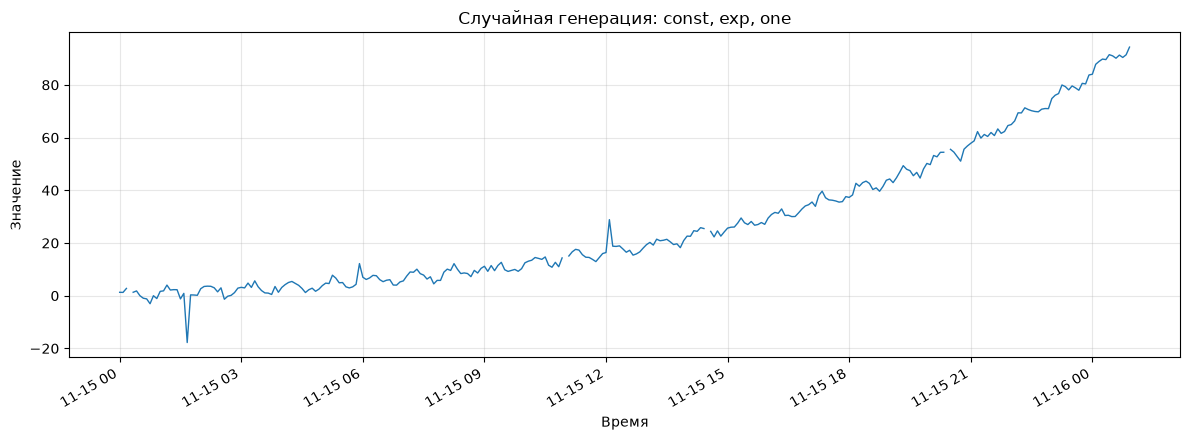

CSV сохранён: .\ts_20261115_171403.csv
JSON сохранён: .\ts_meta_20261115_171403.json


In [3]:
ts, values, meta = generate_time_series(
    n=300, variance="random", trend="random", seasonality="random", sigma0=1.0, seed=123,
    add_outliers=True, outlier_prob=0.02, outlier_scale=8.0,
    add_missing=True, missing_prob=0.01, return_metadata=True
)

print("Метаданные генерации:")
for key, value in meta.items():
    if key in ("outlier_indices", "missing_indices"):
        print(f"{key}: {len(value)} шт.")
    else:
        print(f"{key}: {value}")

plot_series(ts, values, title=f"Случайная генерация: {meta['resolved_variance']}, {meta['resolved_trend']}, {meta['resolved_seasonality']}")
csv_path = save_csv(ts, values, directory=".")
json_path = save_metadata(meta, directory=".")
print("CSV сохранён:", csv_path)
print("JSON сохранён:", json_path)

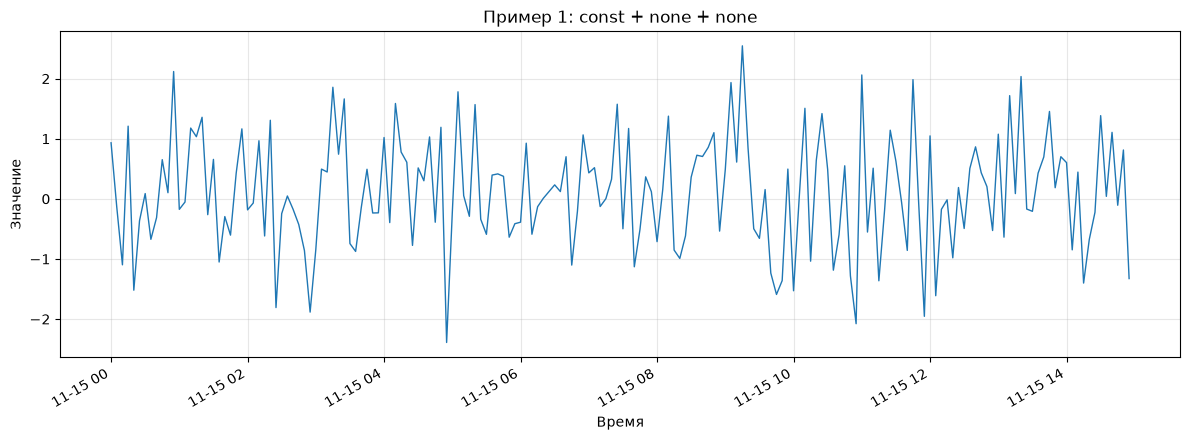

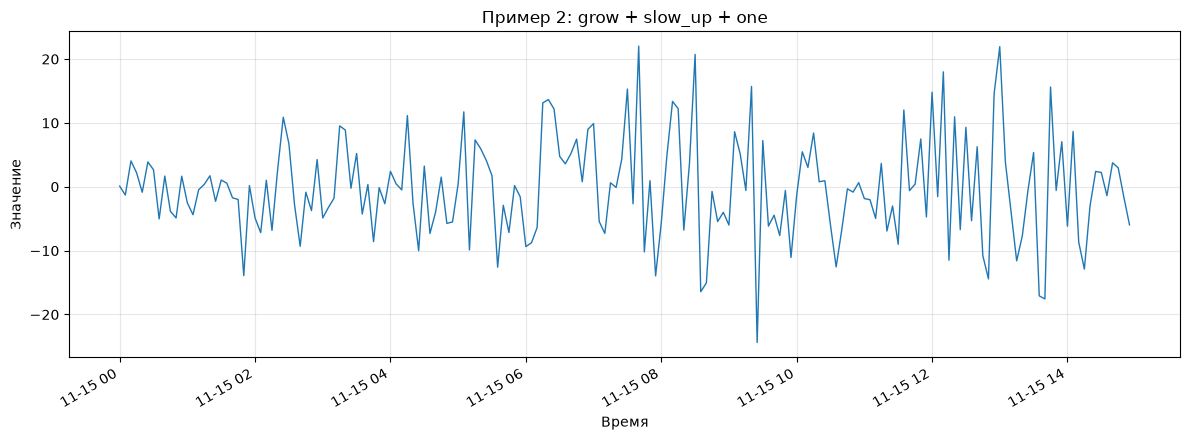

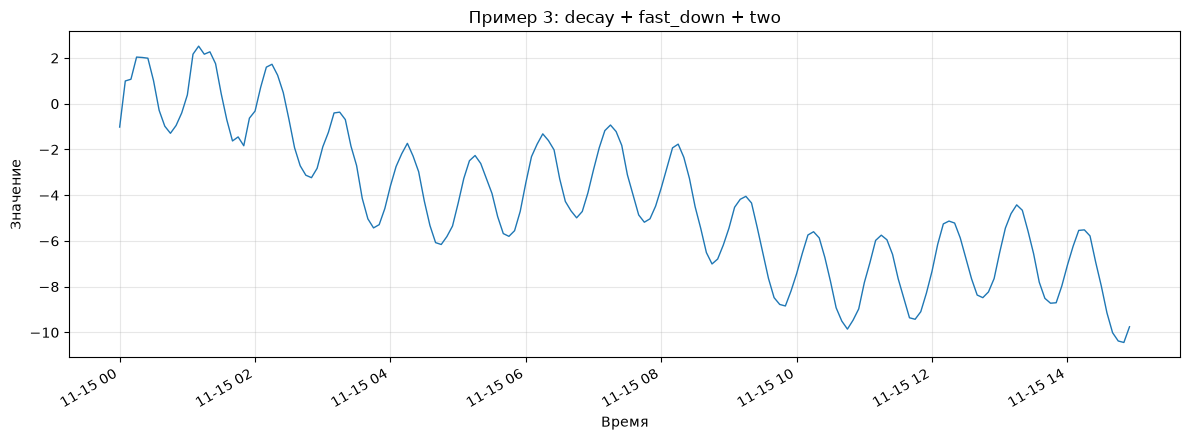

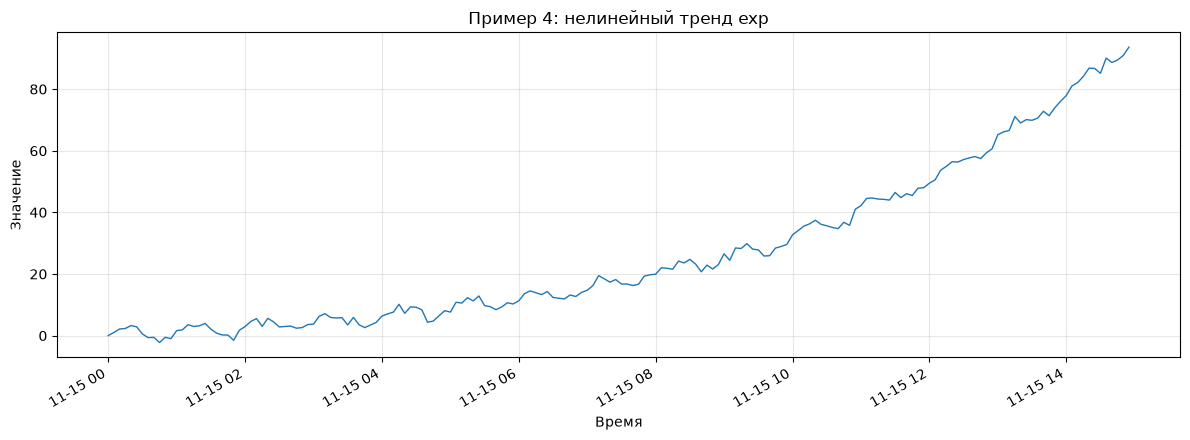

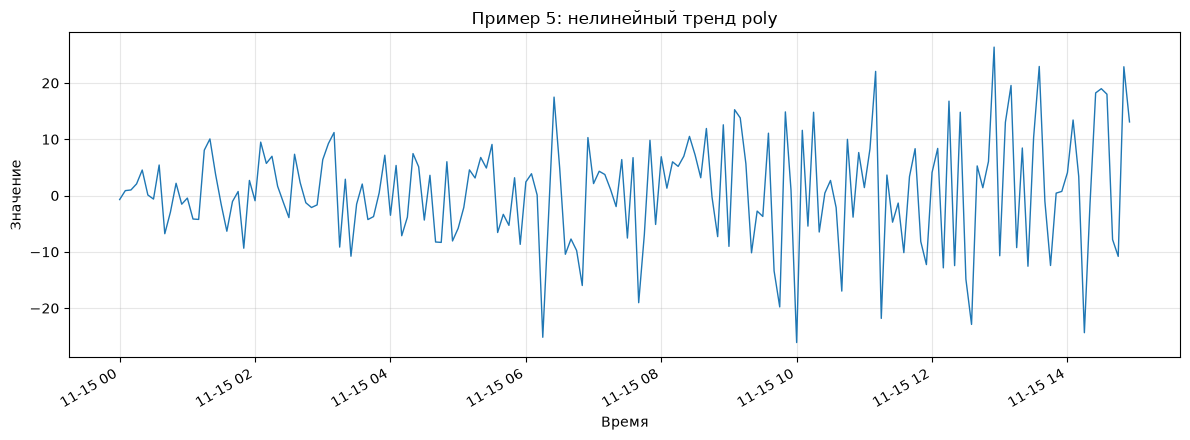

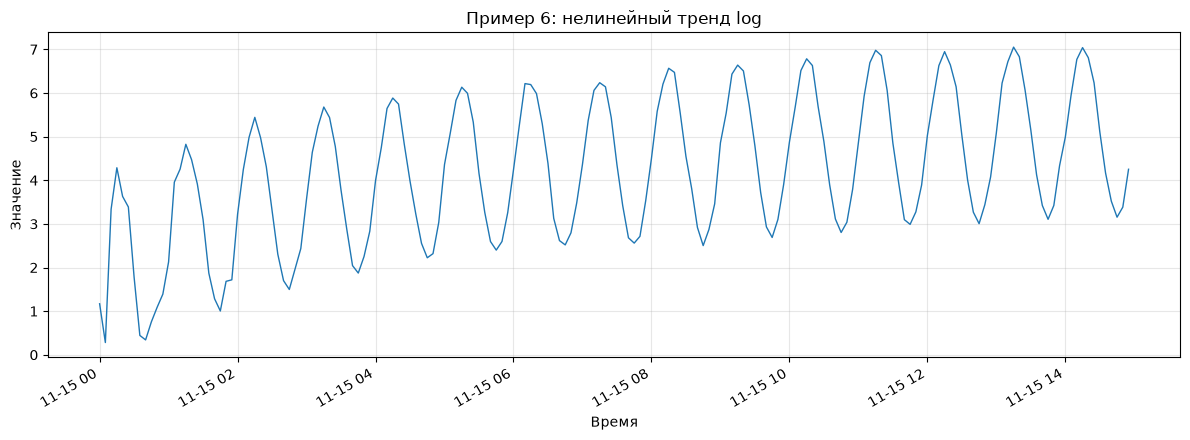

In [4]:
examples = [
    dict(title="Пример 1: const + none + none", params=dict(variance="const", trend="none", seasonality="none")),
    dict(title="Пример 2: grow + slow_up + one", params=dict(variance="grow", trend="slow_up", seasonality="one")),
    dict(title="Пример 3: decay + fast_down + two", params=dict(variance="decay", trend="fast_down", seasonality="two")),
    dict(title="Пример 4: нелинейный тренд exp", params=dict(variance="const", trend="exp", seasonality="one")),
    dict(title="Пример 5: нелинейный тренд poly", params=dict(variance="grow", trend="poly", seasonality="two")),
    dict(title="Пример 6: нелинейный тренд log", params=dict(variance="decay", trend="log", seasonality="one")),
]

for i, example in enumerate(examples, start=1):
    ts_ex, values_ex = generate_time_series(n=180, seed=1000 + i, **example["params"])
    plot_series(ts_ex, values_ex, title=example["title"])

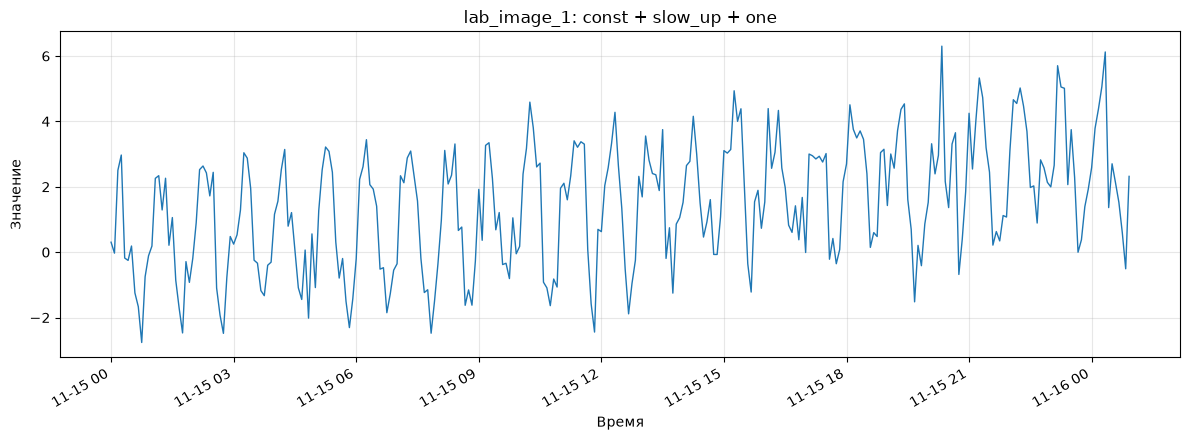

Сохранено: images/lab_image_1.png


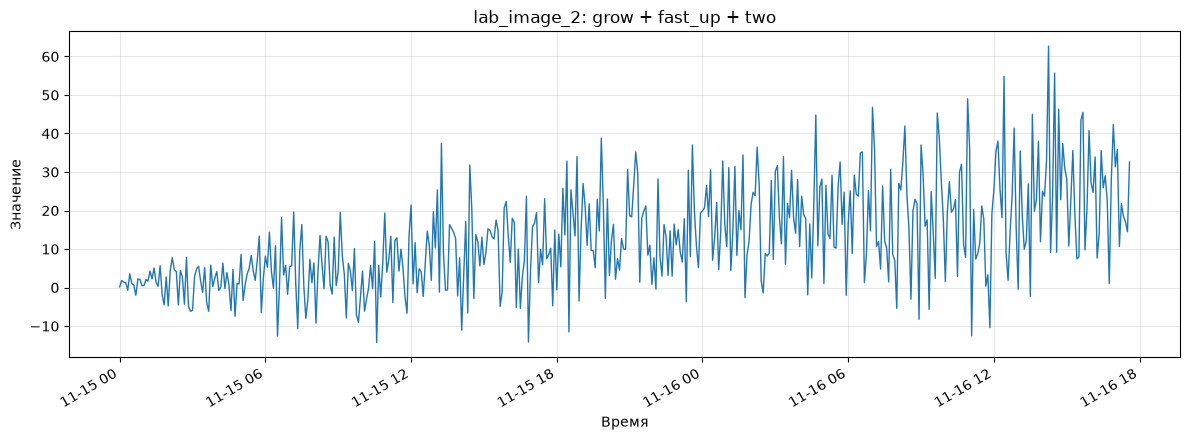

Сохранено: images/lab_image_2.png


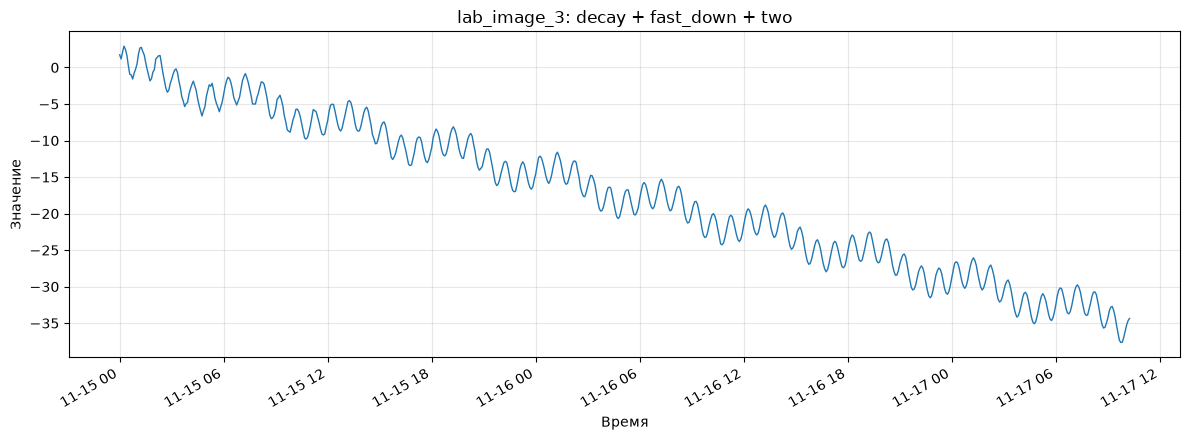

Сохранено: images/lab_image_3.png


In [5]:
report_configs = [
    {"filename": "images/lab_image_1.png", "title": "lab_image_1: const + slow_up + one", "n": 300, "variance": "const", "trend": "slow_up", "seasonality": "one", "sigma0": 1.0, "seed": 42},
    {"filename": "images/lab_image_2.png", "title": "lab_image_2: grow + fast_up + two", "n": 500, "variance": "grow", "trend": "fast_up", "seasonality": "two", "sigma0": 0.7, "seed": 43},
    {"filename": "images/lab_image_3.png", "title": "lab_image_3: decay + fast_down + two", "n": 700, "variance": "decay", "trend": "fast_down", "seasonality": "two", "sigma0": 1.2, "seed": 44},
]

for cfg in report_configs:
    ts_rep, values_rep = generate_time_series(n=cfg["n"], variance=cfg["variance"], trend=cfg["trend"], seasonality=cfg["seasonality"], sigma0=cfg["sigma0"], seed=cfg["seed"])
    plot_series(ts_rep, values_rep, title=cfg["title"], save_path=cfg["filename"])
    print("Сохранено:", cfg["filename"])

## Описание работы программы и дополнительные задания

Программа генерирует ряд по модели $y(t) = T(t) + S(t) + \varepsilon(t)$.
- Временные метки начинаются с `00:00` текущего дня и увеличиваются на 5 минут.
- Количество точек по умолчанию — 1000 (можно передать `n=100` и т.д.).
- Дисперсия: `const`, `grow`, `decay`, `random`.
- Тренд: `none`, `fast_up`, `slow_up`, `fast_down`, `slow_down`, `random`.
- Дополнительные тренды (задание со *): `exp`, `poly`, `log`.
- Сезонность: `none`, `one` (1 час = 12 точек), `two` (1 час + 6 часов = 12 и 72 точки), `random`.
- Результат сохраняется в CSV (`timestamp,value`), графики — в PNG (папка `images`).

**Что было сделано из дополнительного задания:**
1. Добавлены нелинейные тренды: `exp`, `poly`, `log`.
2. Добавлены выбросы (параметры `add_outliers`, `outlier_prob`, `outlier_scale`).
3. Добавлены пропуски (параметры `add_missing`, `missing_prob`), в CSV они записываются пустым значением.
4. Реализовано сохранение метаданных генерации (seed, параметры, индексы выбросов) в JSON-файл.